# 1. Quickstart: price a failure, certify a candidate, write the report

This notebook runs the whole workflow of the toolbox on a small problem, **without training anything**.
It needs only `numpy` and `scipy`. You will

1. state a budget problem and a deployment requirement,
2. see what the clipped barrier reward does and check the identity the paper turns on,
3. get a plan: a starting price, a validation budget, and the conditions under which another method is better,
4. evaluate a few hand-made candidates and place them against the exact frontier,
5. validate a candidate at its horizon and read the report.

Notebook 2 trains a learner through the same wrapper. Section numbers refer to the paper,
*The Price of Failure Risk: Clipped Barrier Policy Gradients with Convex Regularization*.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import bpg
from bpg import BudgetSpec, Requirement, Stage, plan, evaluate, interpret, LogBarrier
from bpg.examples.wear import WearModel, make_wear_env, idle_policy, IncumbentRule, EXACT_FRONTIER, EXACT_BARRIER

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
print("bpg", bpg.__version__, "| paper revision", bpg.PAPER["revision"])

bpg 0.2.0 | paper revision 62


## The problem: an asset operated under a wear allowance

An asset earns revenue in proportion to its **operating rate** $a\in[0,1]$ and a market price index $s$.
Each unit of throughput consumes a random part of a **wear allowance** $b=1$. Exhausting the allowance
before the next maintenance access is a **breakdown**. Maintenance access arrives with probability
$1-\beta=0.05$ per period, so the **geometric risk** $q_\beta=\mathbb E[\beta^\tau 1\{\tau<\infty\}]$ is
exactly the probability of a breakdown before access. Standing still never fails and earns nothing;
every positive rate can fail, because the wear shock is unbounded. This is the paper's running example (Section 3.1).

`BudgetSpec` states the budget, the utility discount $\beta$ and a valid upper bound $\bar u$ on the one-step
utility. Every certificate needs $\bar u$.

In [2]:
model = WearModel()
spec = model.spec(ubar=1.0)
print(spec)

BudgetSpec(budgets=(1.0,), beta=0.95, ubar=1.0, gammas=(1.0,), u_minus=0.0, horizon=None)


## What the clipped barrier reward does

The wrapper carries the remaining reserve $z$ in the state and replaces the reward by
$$r_m=\max\{-m,\;u-B(z')\},\qquad B(z')=\theta\log(1+b/z'),$$
with $z'$ the reserve after the action. An unbounded barrier gives every exploratory policy the value $-\infty$;
clipping at $-m$ keeps returns finite. From failure onward every reward is $-m$, so $m$ is a **price of failure
risk**: one unit of geometric risk costs $m/(1-\beta)$. Before failure, the barrier subtracts an **interior loss**
that buys a margin; a failure-only price ($\theta=0$) charges nothing before failure.

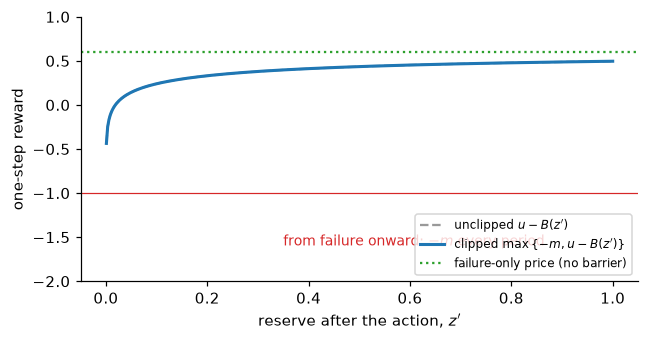

In [3]:
u, m, theta = 0.6, 1.0, 0.15
z = np.linspace(1e-3, 1.0, 400)
B = np.array([LogBarrier(theta, [1.0])([zz]) for zz in z])
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(z, u - B, color="0.6", ls="--", label="unclipped $u-B(z')$")
ax.plot(z, np.maximum(-m, u - B), color="C0", lw=2, label="clipped $\\max\\{-m, u-B(z')\\}$")
ax.axhline(u, color="C2", ls=":", label="failure-only price (no barrier)")
ax.axhline(-m, color="C3", lw=0.8)
ax.annotate("from failure onward: $-m$ every period", (0.35, -m), xytext=(0.35, -1.6), color="C3", fontsize=9)
ax.set_ylim(-2, 1); ax.set_xlabel("reserve after the action, $z'$"); ax.set_ylabel("one-step reward"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

## The identity behind every result

Splitting the discounted sum of clipped rewards at the failure time gives the exact identity
$$V_m=U-\mathcal I_m-\frac{m}{1-\beta}\,q_\beta ,$$
with $U$ the **stopped utility** (earned before failure) and $\mathcal I_m$ the interior loss. Let us check it
on simulated episodes: the wrapper records the clipped return of each episode, and `evaluate` computes the
right-hand side from $U$, $\mathcal I_m$ and the failure indicator.

The wear wrapper uses **geometric stopping**: each period ends the episode with probability $1-\beta$.
A learner with discount one then optimizes the discounted objective exactly, and the failure indicator of an
episode has probability $q_\beta$.

In [4]:
barrier_stage = Stage(m=1.0, theta=0.1)
rule = IncumbentRule(span=1.5, std=0.1, seed=0)          # a rate proportional to the remaining allowance
ev = evaluate(lambda: make_wear_env(barrier_stage, model), rule, 5000, spec=spec, stage=barrier_stage, seed=0)
print(ev.summary())
print(f"\nmean clipped return {ev.clipped_returns.mean():.4f}  vs  U - I_m - m q/(1-beta) = {ev.V_m:.4f}")
print("largest per-episode difference:", float(np.max(np.abs(ev.clipped_returns - ev.V_episodes))))

n=5000: p_T censored by the geometric clock (370 failures counted for q_beta), q_beta=0.074, U=3.991±0.031, I_m=2.991, V_m=-0.4795±0.1, mean length 19.0
near-exhaustion (min reserve <=): 0.02b: 0.101, 0.05b: 0.151, 0.1b: 0.225, 0.2b: 0.348

mean clipped return -0.4795  vs  U - I_m - m q/(1-beta) = -0.4795
largest per-episode difference: 1.4210854715202004e-14


## State the requirement, then plan

The requirement comes first: the breakdown probability within $T+1=20$ periods must stay below $\alpha=5\%$, and
the validation may be wrong with probability $\zeta=5\%$. Several candidates will be validated, so the error is
shared by a **family** of statements.

`plan` turns this into a configuration with reasons. It derives a conservative starting price from the
**price–risk law** (Proposition 3.3(ii)), using a comparison policy that never fails (standing still) and an upper
bound on the utility at stake. It also sizes the validation sample and lists the conditions of Section 1.2
under which another method is the better choice.

In [5]:
req = Requirement(T=19, alpha=0.05, zeta=0.05, family=6)   # six candidates will be inspected
sup_U = EXACT_FRONTIER[0.0][1]          # utility of the unpriced optimum: an upper bound on the utility at stake
p = plan(spec, req, sup_U=sup_U, expected_failure_rate=0.01, validation_H=300, validation_N=20000,
         allowance_error_known=False, failure_permissible_at_deployment=True, structured_solution_available=False)
print(p.explain())

Requirement: p_T <= 0.05 at T = 19 (20 actions), validation error 0.05 shared by 6 statements; kind = finite.
When another method is the better choice [Section 1.2 (When to use the bounded barrier, and when another method)]:
  [does not apply] no deployment failure, or no failure during physical learning, is permissible: an almost-sure formulation (Saute RL with an infinite penalty), a model-based control-barrier safety layer, or a method that learns which actions can satisfy probability-one budget constraints. a finite price prices failure risk; it does not prohibit failure, and a full-support class can have a positive risk floor
  [not stated] a prescribed tolerance is to be met with the least conservatism: a Lagrangian chance-constrained policy gradient that targets the level directly (when it lies above the risk floor). a fixed price leaves the attained risk to the optimizer and unused risk costs utility; the multiplier and learning errors still need control
  [not stated] the requ

The conservative price is large because the law charges the entire utility at stake to the risk. It is a safe
start, not the price to aim for: the certificates and validation bound the risk actually attained, and in the
wear study the law was conservative by a factor of twenty to thirty. Below we use the price $m=1$.

## Candidates against the exact frontier

A **candidate** is one fixed policy that may be deployed. Here the candidates are hand-made rules: standing
still, and rules that run at a rate proportional to the remaining allowance, $a=\min\{1, z/(\text{span}\cdot b)\}$.
The **exact frontier** is the set of (risk, utility) pairs of the exact optima of the failure-only price as $m$
varies, computed by dynamic programming in the paper (Section 6.1). Proposition 3.3(i) says every fixed-price
optimum lies on it: it is optimal at the risk it attains.

In [6]:
stage = Stage(m=1.0)
env = lambda: make_wear_env(stage, model)
candidates = {"idle": idle_policy}
for span in (1.0, 1.5, 2.0, 3.0, 5.0):
    candidates[f"rule, span {span:g}"] = IncumbentRule(span=span, std=0.1, seed=1)
evals = {name: evaluate(env, pol, 6000, spec=spec, stage=stage, seed=10, T=19) for name, pol in candidates.items()}
for name, e in evals.items():
    print(f"{name:14s} q_beta = {e.q_beta:.4f}   U = {e.U:.3f}   near-exhaustion (5% of b) = {e.near[0.05]:.3f}")

idle           q_beta = 0.0000   U = 0.000   near-exhaustion (5% of b) = 0.000
rule, span 1   q_beta = 0.1723   U = 4.648   near-exhaustion (5% of b) = 0.298
rule, span 1.5 q_beta = 0.0710   U = 3.971   near-exhaustion (5% of b) = 0.149
rule, span 2   q_beta = 0.0365   U = 3.467   near-exhaustion (5% of b) = 0.076
rule, span 3   q_beta = 0.0100   U = 2.760   near-exhaustion (5% of b) = 0.024
rule, span 5   q_beta = 0.0013   U = 1.959   near-exhaustion (5% of b) = 0.005


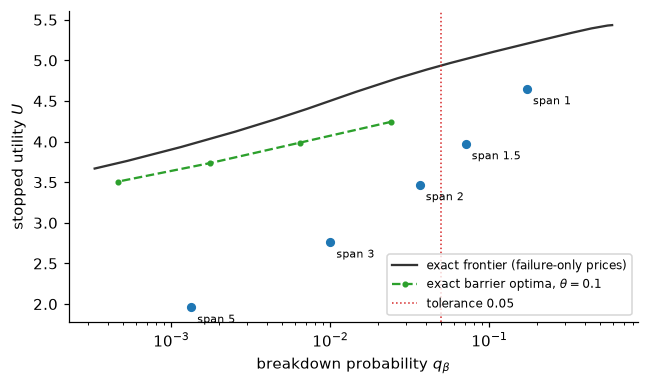

In [7]:
qf = np.array([v[0] for k, v in EXACT_FRONTIER.items()]); Uf = np.array([v[1] for k, v in EXACT_FRONTIER.items()])
order = np.argsort(qf)
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(qf[order], Uf[order], color="0.2", lw=1.5, label="exact frontier (failure-only prices)")
qb = [v[0] for v in EXACT_BARRIER.values()]; Ub = [v[1] for v in EXACT_BARRIER.values()]
ax.plot(qb, Ub, color="C2", ls="--", marker=".", label="exact barrier optima, $\\theta=0.1$")
for name, e in evals.items():
    if name != "idle":
        ax.plot(e.q_beta, e.U, "o", color="C0", ms=5)
        ax.annotate(name.replace("rule, ", ""), (e.q_beta, e.U), textcoords="offset points", xytext=(4, -10), fontsize=7)
ax.axvline(0.05, color="C3", ls=":", lw=1, label="tolerance 0.05")
ax.set_xscale("log"); ax.set_xlabel("breakdown probability $q_\\beta$"); ax.set_ylabel("stopped utility $U$")
ax.legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.show()

The hand-made rules sit inside the frontier: at their risk, a fixed-price optimum earns more. The barrier optima
sit lower still at nominal conditions: their interior loss buys a margin against a misjudged allowance
(notebook 2 measures that margin).

## The price–risk law on the exact solutions

`frontier.check_runs` compares runs at several prices with the price–risk law and with monotonicity in the price
(Proposition 3.3(ii)–(iii)). With exact optimizers the optimization error is zero.

consistent with Proposition 3.3: True


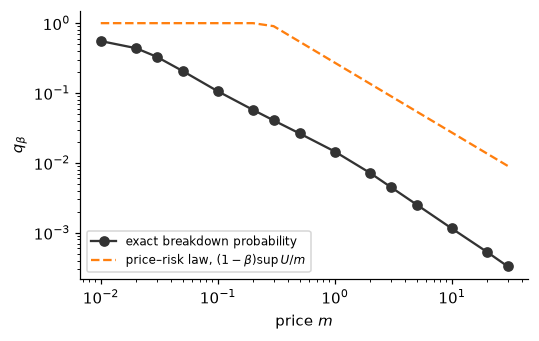

law / exact at m = 1, 10: [18.7, 23.6]


In [8]:
from bpg.frontier import Run, check_runs
runs = [Run(m=mm, q_beta=q, U=U, label="exact") for mm, (q, U) in EXACT_FRONTIER.items() if mm > 0]
chk = check_runs(runs, beta=spec.beta, sup_U=sup_U, delta=0.0)
print("consistent with Proposition 3.3:", chk.consistent)
ms = np.array([r["m"] for r in chk.table]); qs = np.array([r["q_beta"] for r in chk.table]); law = np.array([r["law_bound"] for r in chk.table])
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.loglog(ms, qs, "o-", color="0.2", label="exact breakdown probability")
ax.loglog(ms, law, "--", color="C1", label="price–risk law, $(1-\\beta)\\sup U/m$")
ax.set_xlabel("price $m$"); ax.set_ylabel("$q_\\beta$"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()
print("law / exact at m = 1, 10:", [round(float(l / q), 1) for l, q, mm in zip(law, qs, ms) if mm in (1.0, 10.0)])

The bound has the right dependence on the price, order $1/m$, and is conservative by a factor of about twenty.

## Validate the candidate that would be deployed

Validation is the deployment decision. Draw fresh episodes of the fixed candidate and compute a one-sided exact
binomial upper bound on its failure probability. Zero failures in $N$ episodes certify the **resolution floor**
$1-\zeta^{1/N}$, never zero. The error $\zeta$ is split over the family of candidates inspected, before any is
selected. Failure to certify does not prove a violation.

Under geometric stopping the episode clock censors the finite-horizon risk $p_T$, so the toolbox validates
$q_\beta$ and uses $p_T\le\beta^{-T}q_\beta$. Notebook 4 shows how to validate $p_T$ directly.

In [9]:
for name, e in evals.items():
    v = e.validate(req.alpha * spec.beta ** req.T, req.zeta, req.family)
    print(f"{name:14s} {v.failures:4d} failures / {v.n}: upper bound on q_beta {v.upper:.4f} -> "
          f"{'certifies' if v.passed else 'does not certify'} p_19 <= 0.05 (floor {v.floor:.4f})")

idle              0 failures / 6000: upper bound on q_beta 0.0008 -> certifies p_19 <= 0.05 (floor 0.0008)
rule, span 1   1034 failures / 6000: upper bound on q_beta 0.1843 -> does not certify p_19 <= 0.05 (floor 0.0008)
rule, span 1.5  426 failures / 6000: upper bound on q_beta 0.0793 -> does not certify p_19 <= 0.05 (floor 0.0008)
rule, span 2    219 failures / 6000: upper bound on q_beta 0.0427 -> does not certify p_19 <= 0.05 (floor 0.0008)
rule, span 3     60 failures / 6000: upper bound on q_beta 0.0135 -> certifies p_19 <= 0.05 (floor 0.0008)
rule, span 5      8 failures / 6000: upper bound on q_beta 0.0030 -> certifies p_19 <= 0.05 (floor 0.0008)


## The report

`interpret` writes what the evidence establishes for one candidate and what it does not. When the optimization
error is unknown (`delta=None`), as for a hand-made rule, the report makes no optimality claim; validation is the
operative evidence.

In [10]:
inc = evals["rule, span 3"]
rep = interpret(spec, req, stage, inc, sup_U=sup_U, delta=None, candidate_name="the span-3 rule")
print(rep.text())

Candidate under price m = 1; requirement p_19 <= 0.05 at error 0.05/6.

Measured on fresh episodes:
  n=6000: p_T censored by the geometric clock (60 failures counted for q_beta), q_beta=0.01, U=2.76±0.024, I_m=0, V_m=2.56±0.032, mean length 20.1
  near-exhaustion (min reserve <=): 0.02b: 0.0147, 0.05b: 0.0243, 0.1b: 0.0448, 0.2b: 0.104

Verdict: CERTIFIED by direct validation at the specified horizon.

In what sense the candidate is a solution:
  - Optimization error is unknown: no optimality or convergence claim is made for this candidate. The finite-price objective trades stopped utility and interior loss against failure risk; direct validation assesses the executed candidate independently of optimization.

Evidence and bounds:
  - direct validation under the geometric clock: 60 failures in 6000 episodes; exact binomial upper endpoint 0.01352 on q_beta at error 0.00833 (resolution floor 0.000798)
  - finite-horizon requirement validated through q_beta <= alpha beta^T = 0.01887: pass

## Summary

* The price sets the risk attained; it does not prescribe a level. The price–risk law gives a safe starting price.
* The identity $V_m=U-\mathcal I_m-\tfrac{m}{1-\beta}q_\beta$ is exact; every certificate rests on it.
* Validation of the deployed candidate, with the error shared across the candidates inspected, is the deployment decision.

Next: **notebook 2** trains PPO through the wrapper and measures how close it gets to the exact frontier.